# Plotting of Calyculin treatment experiment for revisions

In [1]:
%matplotlib inline

"""
Utility cell : loading all the important functions 
"""


# Imports

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import subprocess
import re
from scipy import stats
from statannot import add_stat_annotation
import datetime


# Increase the fontsize globally 
#sns.set(rc={"font.size":40})
sns.set(font_scale=1.8)
#sns.set_style('ticks')
# Utility functions



def list_files(csv_folder_path):
    files_list = []
    for root, directory, filenames in os.walk(csv_folder_path):
        for filename in filenames:
#            print(os.path.join(root, filename))
            files_list.append(os.path.join(root, filename))
    return files_list

def get_dataframes_list_from_xlsx_folder(xlsx_folder_path, experiment_name=""):
    
    # Load the data
    xlsx_files_list = list_files(xlsx_folder_path)
    dataframes_list = []
    for file in xlsx_files_list:
        # Read the xlsx file and gets the content in a DataFrame
        xlsx_df = pd.read_excel(file)
        if experiment_name is "":
            xlsx_df['File_label'] = os.path.basename(file)
        else:
            xlsx_df['File_label'] = os.path.basename(file) + "_" + experiment_name
        dataframes_list.append(xlsx_df)
        # Add a label to the dataframe with the file name
        
   
    return dataframes_list 
    
def savefigure(figure_path, figure_name):
    """
    Save the figure in png and svg formats
    
    Parameters:
    ------
    figure_path : str, path to the desired save folder
    figure_name : str, name of the figure
    """
     
    path_to_inkscape = "C:\\Program Files\\Inkscape\\bin\\inkscape.exe"
    
    plt.savefig(figure_path + figure_name + '.svg', bbox_inches='tight')
    plt.savefig(figure_path + figure_name + '.png', bbox_inches='tight')   
    
    # Calls Inkscape as a subprocess to create an emf version of the figure, based on the previously created .svg
    svgFile = os.path.join(figure_path, figure_name+".svg")
    emfFile = os.path.join(figure_path, figure_name+".emf")
    subprocess.call([path_to_inkscape, svgFile, "--export-filename", emfFile], shell=True)   
 
    
    
    
def prepare_multiwell_dataframe(csv_folder, experiment_name):
    """
    Performs parsing of a folder containing csv files describing the polygon segmentations of organoids
    Sort the results of the parsing into a DataFrame

    Parameters
    ------
    csv_folder : str, path to the csv folder containing the csv files
    experiment_name : str, name of the experiment
    
    Returns : 
    
    csv_df : pandas dataframe, contains the entire processed data from the csv files
    
    """
    csv_df = get_dataset_from_csv_folder(csv_folder)
    print(csv_df.head)
    roi_list = list(csv_df['Label'])                    


    full_id_list, well_list, organoid_id_list, well_id_plus_organoid_id_list, timestamp_list = parse_id_multiwell(roi_list)
    
    csv_df['Full_id'] = full_id_list
    csv_df['Well'] = well_list
    csv_df['Organoid_id'] = organoid_id_list
    csv_df['Well_and_Organoid_id'] = well_id_plus_organoid_id_list
    csv_df['Date'] = timestamp_list
    
    # For further comparisons between datasets, save the loaded df
    csv_df['Experiment_name'] = experiment_name
    
    # Conversion steps for merging
    csv_df = csv_df.astype({'Date' : 'int64'})

    return csv_df



def add_time_column(df, frame_to_time_conversion, frame_drug_added, name_time_frame_column="First, Time Point"):
    """
    Takes an existing dataframe where time is only labelled in frame number and creates new columns with frame numbers converted to 
    sec/min/hours.
    
    Parameters
    ------
    df : pandas DataFrame
    frame_to_time_conversion : int/float, interval between two frames in seconds
    frame_drug_added : int, frame number at which the drug is added. By convention, the first image when restarting the imaging after drug addition is considered as the "zero"
     
    Returns
    ------
    df : updated DataFrame with new columns (["Time (sec)"], ["Time (min)"], ["Time (hours)"], ["Time with offset (sec)"], ["Time with offset (min)"], ["Time with offset (hours)"])
    """
    
    df["Time (sec)"] = df["First, Time Point"] * frame_to_time_conversion
    df["Time (min)"] = df["First, Time Point"] * (frame_to_time_conversion / 60.0)
    df["Time (hours)"] = df["First, Time Point"] * (frame_to_time_conversion / 3600.0)

    df["Time with offset (sec)"] = (df["First, Time Point"] - frame_drug_added) * frame_to_time_conversion
    df["Time with offset (min)"] = (df["First, Time Point"] - frame_drug_added) * (frame_to_time_conversion / 60.0)
    df["Time with offset (hours)"] = (df["First, Time Point"] - frame_drug_added) * (frame_to_time_conversion / 3600.0)
    
    
    return df



def quickplot_lineplot(df, x_param, y_param, vline=False, vline_xpos=0):
    """
    Quick shorthand function to generate a seaborn plot from an existing DataFrame
    
    Parameters
    -------
    df : pandas DataFrame
    x_param : str, the name of the column in the DataFrame to plot on the x-axis
    y_param : str, the name of the column in the DataFrame to plot on the y-axis
    vline : bool, set to True if you want to plot a vertical line indicating when the drug was added (for instance)
    vline_xpos = int/float, indicates the position on the x-axis at which to plot the vertical line
    
   
    Returns
    ------
    g : seaborn plot 
    """

#    plt.figure()

    g = sns.lineplot(x=x_param, y=y_param,
                     marker='o',
                     data=df)

    if vline==True:
        # Insert a vertical line indicating the time at which the drug was added
        ## Careful, on a pointplot, the indexing is weird, so the x coordinate of the vertical line would need to be reworked
        ymin, ymax = g.get_ylim()
        g.vlines(x=time_drug_addition_offset, ymin=ymin, ymax=ymax, colors="tab:orange", ls='--', lw=2)
        
        
    # Labelling     
    plt.xlabel(x_param)
    plt.title("{} over time)".format(y_param))
    plt.xticks(rotation=45, ha='right')
    sns.despine()
     
    return g
#    plt.show()


def prepare_normalized_shape_column(original_df, shape_columns_list, name_time_frame_column, provided_reference_frame=None):
    
    df_grouped = original_df.groupby(["File_label"])
    groups_df_grouped = dict(list(df_grouped))
    df_list = []
    for key in groups_df_grouped.keys():
        
        # Treat one df at a time
#        print(key)
        df = groups_df_grouped[key]
        
        # If no specific reference frame is provided, pick the first available one
        if provided_reference_frame is None:
            # Do a sorting by time to really be sure to pick the first available frame 
            df.sort_values(by=[name_time_frame_column])
#            print(df.head())
            reference_frame = df[name_time_frame_column][0]
#            print("Selecting the first available time frame ({}) for normalization.".format(reference_frame))
        
        else:
            reference_frame = provided_reference_frame
        
        
        for shape in shape_columns_list:
#            print(shape)
            # Don't forget to add the .values[0] to select the actual value and not the full index 
            # Possibly the frame_drug_added is missing

                
            try:
                ref_value = df[shape].loc[df[name_time_frame_column] == reference_frame]
                ref_value = ref_value.values[0]
#                print("ref_value is : ", ref_value, "at reference frame ", reference_frame )
            except IndexError:
                print("The corresponding value for the selected reference frame (Frame {0}) is missing ".format(reference_frame))
                
            try:
                df["Normalized " + shape] = df[shape] / ref_value
            except ZeroDivisionError:
                print("Ref value is zero")

        df_list.append(df)
        print("-"*20)
    
    return pd.concat(df_list)


def check_for_zero_match(checklist, series):
    """
    When creating a pandas Series using a .loc statement, an absence of match can result in the omission of a row of interest from the Series. 
    This function parses the obtained series and check that every row in the desired checklist is present. 
    If a row is missing, this function will append it to the series with a zero.
    
    Parameters
    ---------
    checklist : list of rows that you wish to be present in the series
    series : Pandas Series, to treat 
    
    Returns
    -------
    series : Pandas Series, with the appended missing rows if needed
    """
    for row in checklist:
        if row not in series:
            series.at[row] = 0
            
    return series

def prepare_treatment_percentage_df(condition_size_series, total_size_series, condition_column_name="Treatment", yes_column_name="Forming lumen after treatment"):
    """
    Convenience function.
    Takes two pandas series (with a Yes/No condition) and returns a dataframe with computed percentages
    """
     
    # Transform this into percentages - This a pandas Series at this point
    yes_percentage_series = (condition_size_series/total_size_series) * 100

    # We consider forming lumens to be a YES/NO problem, so we can create the complement
    no_percentage_series = 100 - yes_percentage_series


    # Transform the Series into dataframes
    yes_percentage_df = pd.DataFrame({condition_column_name: yes_percentage_series.index, "Percentage":yes_percentage_series.values})
    no_percentage_df = pd.DataFrame({condition_column_name: no_percentage_series.index, "Percentage":no_percentage_series.values})

    # Add a Lumen/No Lumen column
    yes_percentage_df[yes_column_name] = "Yes"
    no_percentage_df[yes_column_name] = "No"

    # Create a merged DataFrame to simplify the call
    merged_df = pd.concat([yes_percentage_df, no_percentage_df])
       
    return merged_df




def prepare_batch_weighted_df(excel_df, treatment_column_name="Drug concentration", batch_column_name="Batch_Well_ID", condition_column_name="Large lumens visible after drug addition (Yes/No/Uncertain)"):
    """
    Convenience function to add weighted statistics to a dataframe  
    
    Parameters
    -------
    excel_df : pandas DataFrame. The DataFrame, masked or not, loaded from the Excel (or csv) data.
    treatment_column_name : str. The name of the column along which you want your groups on the x-axis (e.g. grouped by treatment).
    batch_column_name : str. The name of the batch column along which you want to average (e.g. computing the weighted average for each batch within a similar treatment group)
    condition_column_name : str. The name of the condition that you want to measure (e.g. the presence or not of a lumen, or dead Yes/No)
    
    
    Returns 
    -------
    df : pandas DataFrame. A copy of the loaded excel_df with new columns for the weighted and un-weighted fractions.
    stats_df: pandas DataFrame. A convenience DataFrame summarising the weighted mean and standard error of the weighted mean, assuming iid variables.
    """
   
    
    
    ## Population count, for each concentration, grouped by Batch_Well_ID, and depending on lumen formation
    ### We use reset_index() to get at DataFrame out of the groupby function
    df = excel_df.groupby([treatment_column_name, batch_column_name, condition_column_name]).size().reset_index(name="Count")

    df = check_for_complements(df, treatment_column_name="Drug concentration", batch_column_name="Batch_Well_ID", condition_column_name="Large lumens visible after drug addition (Yes/No/Uncertain)", count_column_name="Count")
    
    
    # Compute the ratios over total
    df["Total pop in the batch"] = df.groupby(batch_column_name)["Count"].transform("sum")

    ### Compute total size in the condition
    df["Total pop in the condition"] = df.groupby(treatment_column_name)["Count"].transform("sum")
    ### Compute weight per batch : weight : batch size/total size
    df["Weight"] = df["Total pop in the batch"]/df["Total pop in the condition"]

    ### Compute unweighted fraction per batch : 
    df["Batch-unweighted fraction"] = df["Count"]/df["Total pop in the batch"]
    
    
    ### Compute weighted fraction per batch : 
    df["Batch-weighted fraction"] = df["Weight"] * df["Count"]/df["Total pop in the batch"]

    # Compute the mean percentages of lumen forming (and not forming) after drug addition, by averaging across (batches)

   
    ### Create the weighted mean stats dataframe and compute the unweighted standard deviation
    
    stats_df = df.groupby([treatment_column_name, condition_column_name]).agg({"Batch-weighted fraction":"sum", "Batch-unweighted fraction":"std"}).reset_index()
    stats_df.rename(columns={"Batch-weighted fraction":"Lumen formation fraction weighted mean", "Batch-unweighted fraction":"Unweighted standard deviation"}, inplace=True)  # Rename the columns
    
#    print("Stats DataFrame")
#    print(stats_df)

    # Compute weighted std dev = unweighted std dev * sum of squared weights
    df["Squared weights"] = df["Weight"] ** 2
    ## Create a temp df to generate the summed squared weights column
    temp_df = df.groupby([treatment_column_name, condition_column_name])["Squared weights"].sum().reset_index(name="Summed squared weights")
    
#    print("Summed squared temporary DataFrame")
#    print(temp_df.columns)
#    print(temp_df)
    stats_df["Summed squared weights"] = temp_df["Summed squared weights"] # Add the newly computed column of summed squared weights
    stats_df["Standard error of the weighted mean (weighted std dev)"] = stats_df["Unweighted standard deviation"] * stats_df["Summed squared weights"]
    
#    print("Updated stats DataFrame")
#    print(stats_df)   

    ### Multiply by 100 to get percents
    stats_df["Lumen formation weighted mean (%)"] = 100 * stats_df["Lumen formation fraction weighted mean"]
    stats_df["Standard error of the weighted mean (weighted std dev, %)"] = 100 * stats_df["Standard error of the weighted mean (weighted std dev)"]
    

    return df, stats_df 

 
def check_for_complements(df, treatment_column_name="Drug concentration", batch_column_name="Batch_Well_ID", condition_column_name="Large lumens visible after drug addition (Yes/No/Uncertain)", count_column_name="Count"):
    """
    Checking that every condition and each batch has Yes/No data for the outcome being looked at (e.g. whether lumens are forming).
    If only one of the outcome has data, set its complement to 0.
    
    Parameters
    -------
    df : pandas DataFrame. The DataFrame to process.
    treatment_column_name : str. The name of the column along which you want your groups on the x-axis (e.g. grouped by treatment).
    batch_column_name : str. The name of the batch column along which you want to average (e.g. computing the weighted average for each batch within a similar treatment group)
    condition_column_name : str. The name of the condition that you want to measure (e.g. the presence or not of a lumen, or dead Yes/No)
    count_column_name : str. The name of the column containing the counts for the measured outcome.
    
    Returns
    --------
    df : pandas DataFrame. The updated and sorted DataFrame containing the complemented data.
    
    """
    # Check that for every conditions and each batch, there is an outcome and its complement ()
    complements_to_add  = []
    for treatment in df[treatment_column_name].unique():
        for batch in df[batch_column_name].loc[df[treatment_column_name] == treatment].unique():
            for condition in ["Yes", "No"]:
        # Probably more effective to initialise a dictionary or a list and then merge once at the end
                if (df.loc[(df[treatment_column_name] == treatment) & (df[batch_column_name] == batch) & (df[condition_column_name] == condition)].empty):
                    print(f"Didn't find the {condition} condition for batch {batch}, at {treatment}. Adding the complement and setting the count to 0")
                    dict_to_add = {treatment_column_name:treatment, batch_column_name:batch, condition_column_name:condition, count_column_name:0}
                    complements_to_add.append(dict_to_add)
    
    rows_to_add = pd.DataFrame(complements_to_add)
    df = pd.concat([df, rows_to_add], ignore_index=True)
    
    df.sort_values(by=[treatment_column_name, batch_column_name, condition_column_name], ascending=[True, True, False], inplace=True)
                    
    return df
                
  

./Graphs/Revisions/
calyculin_analysis.xlsx


No handles with labels found to put in legend.


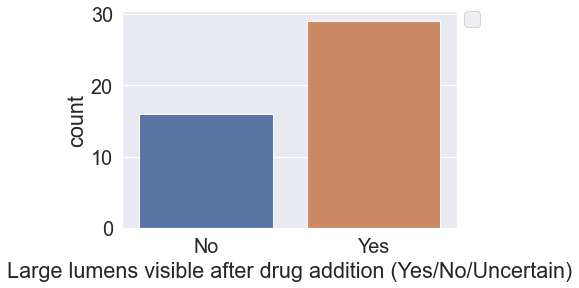

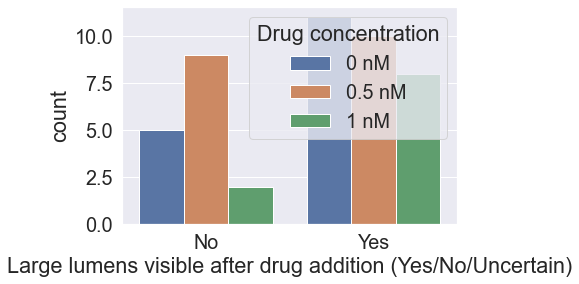

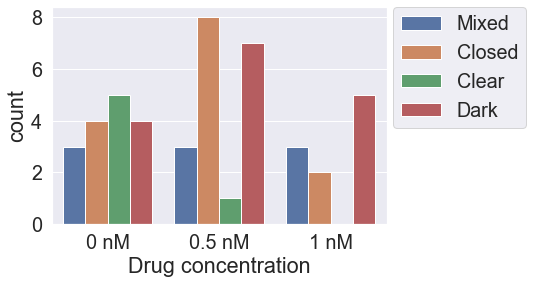

In [2]:
"""
Loading the Excel file containing the observations
"""

## Folder to save produced graphs
graphs_folder = "./Graphs/Revisions/"
print(graphs_folder)
## Loading dataset
measurement_file = "calyculin_analysis.xlsx"
print(measurement_file)



excel_df = pd.read_excel(measurement_file,sheet_name="Sheet1")

# We define a list of columns that should not contain NA values to be processed
list_columns_not_na = ["Large lumens visible before drug addition", "Large lumens visible after drug addition (Yes/No/Uncertain)", "The phenotype would, in normal conditions, reasonably be expected to form large lumens within the duration of the video"]

# Drop inplace the rows containing the NA values not suitable for analysis
excel_df.dropna(subset=list_columns_not_na, inplace=True)
excel_df.sort_values(by=["Drug concentration", "Large lumens visible after drug addition (Yes/No/Uncertain)"], inplace=True)

# Sort along the drug concentration for ease of plotting
#print(excel_df.head)

# Define a mask to consider solely the phenotypes that would form a lumen without the drug but also following drug treatment.
lumen_normally_col = "The phenotype would, in normal conditions, reasonably be expected to form large lumens within the duration of the video"
lumen_post_drug_col = "The phenotype following drug addition would be expected to form lumens"
#expected_lumen_mask = excel_df["The phenotype would, in normal conditions, reasonably be expected to form large lumens within the duration of the video"] == "Yes" # For the only pre-drug version
# expected_lumen_mask = excel_df[lumen_normally_col] == "Yes" # For the only pre-drug version
expected_lumen_mask = (excel_df[lumen_normally_col] == "Yes") | (excel_df[lumen_post_drug_col] == "Yes") # To consider phenotypes that would form lumens even without the drug OR with the drug

#sns.countplot(x="Drug", hue="Large lumens visible after drug addition (Yes/No/Uncertain)", data=excel_df)
sns.countplot(x="Large lumens visible after drug addition (Yes/No/Uncertain)", data=excel_df)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

plt.figure()
sns.countplot(x="Large lumens visible after drug addition (Yes/No/Uncertain)", hue="Drug concentration", data=excel_df)

plt.figure()
sns.countplot(x="Drug concentration", hue="Lumen phenotype (Clear/Dark/Mixed/Closed)", data=excel_df)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
#sns.countplot(x="Lumen phenotype (Clear/Dark/Mixed/Closed)", hue="Drug concentration", data=excel_df)

## Note : Calyculin appears to induce an arrest of the Extension phase and a thickening of the organoids. 
## As such we have also taken into consideration phenotypes that would form not form lumens in normal conditions (e.g. because they are initially too thin), but that, after drug addition, reach a phenotype that could allow lumen formation.

# Plotting the histograms with separated drug concentrations

There are 12 organoids in the 0 nM group, out of which 11 form lumens after the 0 nM 'treatment' 
There are 13 organoids in the 0.5 nM group, out of which 10 form lumens after the 0.5 nM 'treatment' 
There are 8 organoids in the 1 nM group, out of which 8 form lumens after the 1 nM 'treatment' 


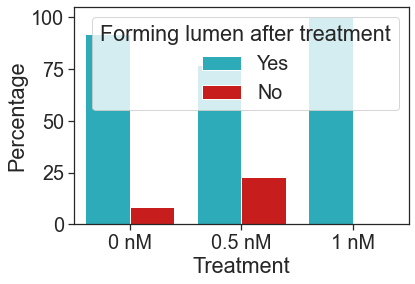

In [3]:
############################
#### Computing the frequency of lumen apparition in a histogram 
####
############################

# Compute the sizes

## Total population (for each concentration)
size_expected_lumen_groupby_concentration = excel_df.loc[(expected_lumen_mask)].groupby("Drug concentration").size() 
## Population forming lumens (for each treatment)
size_expected_lumen_forming_lumen_groupby_concentration = excel_df.loc[(expected_lumen_mask) & (excel_df["Large lumens visible after drug addition (Yes/No/Uncertain)"] == "Yes")].groupby("Drug concentration").size()

## Make sure that every row is present
drug_concentration_list = excel_df["Drug concentration"].unique()
size_expected_lumen_groupby_concentration = check_for_zero_match(drug_concentration_list, size_expected_lumen_groupby_concentration)
size_expected_lumen_forming_lumen_groupby_concentration = check_for_zero_match(drug_concentration_list, size_expected_lumen_forming_lumen_groupby_concentration)
    
# Print the number of organoids forming lumens after treatment
for treatment, total_size, treatment_2, lumen_forming_size in zip(size_expected_lumen_groupby_concentration.index, size_expected_lumen_groupby_concentration.values, 
                                                                  size_expected_lumen_forming_lumen_groupby_concentration.index, size_expected_lumen_forming_lumen_groupby_concentration.values):
    print("There are {} organoids in the {} group, out of which {} form lumens after the {} 'treatment' ".format(total_size, treatment, lumen_forming_size, treatment_2))
    
    
# Create a merged DataFrame to simplify the call
merged_df_per_concentration = prepare_treatment_percentage_df(size_expected_lumen_forming_lumen_groupby_concentration,
                                      size_expected_lumen_groupby_concentration,
                                      "Treatment", 
                                      "Forming lumen after treatment")


# Non despined
with sns.axes_style("ticks"):
    plt.figure()
    sns.barplot(x="Treatment", y="Percentage", hue="Forming lumen after treatment", data=merged_df_per_concentration,
               palette=["tab:cyan", "xkcd:red"]
               )
    savefigure(graphs_folder, "forming_lumen_after_treatment_per_concentration")
 

# Looking only at organoids that did NOT have a lumen prior to lumen addition

There are 11 organoids in the 0 nM group, out of which 10 form lumens after the 0 nM 'treatment' 
There are 10 organoids in the 0.5 nM group, out of which 7 form lumens after the 0.5 nM 'treatment' 
There are 7 organoids in the 1 nM group, out of which 7 form lumens after the 1 nM 'treatment' 


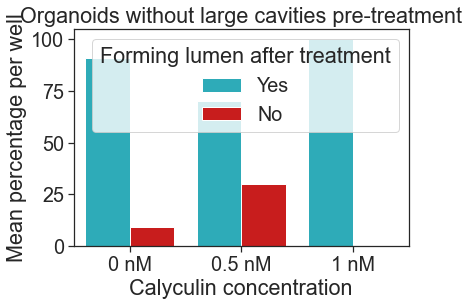

In [4]:
############################
#### Computing the frequency of lumen apparition in a histogram 
#### and look ONLY for organoids that did not display a large lumen before treatment
############################

# Compute the sizes
no_large_lumen_before_mask = excel_df["Large lumens visible before drug addition"] == "No"

## Total population (for each concentration)
size_expected_lumen_no_large_lumen_before_groupby_concentration = excel_df.loc[(expected_lumen_mask) & (no_large_lumen_before_mask)].groupby("Drug concentration").size() 
## Population forming lumens (for each treatment)
size_expected_lumen_no_large_lumen_before_forming_lumen_groupby_concentration = excel_df.loc[(expected_lumen_mask) & (no_large_lumen_before_mask) & (excel_df["Large lumens visible after drug addition (Yes/No/Uncertain)"] == "Yes")].groupby("Drug concentration").size()
    
    
## Problem with the previous call : if there is ZERO match for the loc conditions, it will NOT get included in the Series
## To solve this, we assume that the previous call is perfectly written (i.e. that the absence of a row is really due to ZERO match, and not a badly written statement)
## Look if every unique identifier is present and if not, append it with a zero in the Series
## Make sure that every row is present
drug_concentration_list = excel_df["Drug concentration"].unique()
size_expected_lumen_no_large_lumen_before_groupby_concentration = check_for_zero_match(drug_concentration_list, size_expected_lumen_no_large_lumen_before_groupby_concentration)
size_expected_lumen_no_large_lumen_before_forming_lumen_groupby_concentration = check_for_zero_match(drug_concentration_list, size_expected_lumen_no_large_lumen_before_forming_lumen_groupby_concentration)

# Print the number of organoids forming lumens after treatment
for treatment, total_size, treatment_2, lumen_forming_size in zip(size_expected_lumen_no_large_lumen_before_groupby_concentration.index, size_expected_lumen_no_large_lumen_before_groupby_concentration.values, 
                                                                  size_expected_lumen_no_large_lumen_before_forming_lumen_groupby_concentration.index, size_expected_lumen_no_large_lumen_before_forming_lumen_groupby_concentration.values):
    print("There are {} organoids in the {} group, out of which {} form lumens after the {} 'treatment' ".format(total_size, treatment, lumen_forming_size, treatment_2))
 

# Create a merged DataFrame to simplify the call
percentage_df = prepare_treatment_percentage_df(size_expected_lumen_no_large_lumen_before_forming_lumen_groupby_concentration,
                                      size_expected_lumen_no_large_lumen_before_groupby_concentration,
                                      "Treatment", 
                                      "Forming lumen after treatment")

# Non despined
with sns.axes_style("ticks"):
    plt.figure()
    sns.barplot(x="Treatment", y="Percentage", hue="Forming lumen after treatment", data=percentage_df,
               palette=["tab:cyan", "xkcd:red"])
    plt.title("Organoids without large cavities pre-treatment")
    plt.xlabel("Calyculin concentration")
    plt.ylabel("Mean percentage per well")
   # savefigure(graphs_folder, "no_lumen_before_treatment_forming_lumen_after_treatment_per_concentration")

# Compute the batch means and average 

Didn't find the No condition for batch 220919_A6, at 0 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 220919_D6, at 0 nM. Adding the complement and setting the count to 0
Didn't find the Yes condition for batch 220919_D3, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 221003_D3, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 220919_D1, at 1 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 221003_D1, at 1 nM. Adding the complement and setting the count to 0
Looking at 0 nM
Looking at 0.5 nM
Looking at 1 nM


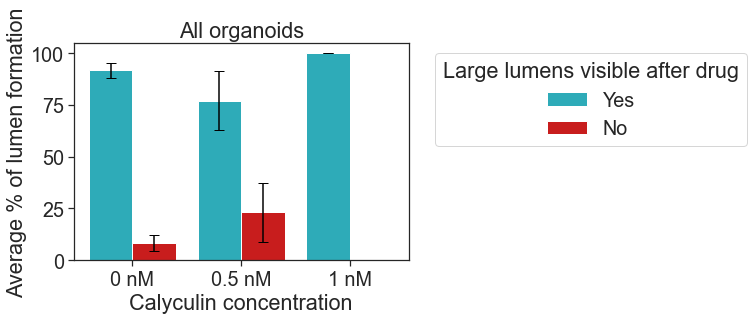

In [5]:
############################
#### Consider all organoids
############################

# Compute the sizes

## Population count, for each concentration, grouped by Batch_Well_ID, and depending on lumen formation

############## Function rework


# Load the masked df for organoids expected to form a lumen
df, mean_sewm_df = prepare_batch_weighted_df(excel_df.loc[(expected_lumen_mask)], treatment_column_name='Drug concentration', batch_column_name='Batch_Well_ID', condition_column_name='Large lumens visible after drug addition (Yes/No/Uncertain)')


#####################################

## Indicate the "Large lumens visible" column
lumen_formed_column = "Large lumens visible after drug addition (Yes/No/Uncertain)"


## Re-sort the dataset to correctly add the error bars afterwards.
mean_sewm_df.sort_values(by=["Drug concentration", lumen_formed_column], ascending=[True,False], inplace=True)

###############################
##### Plotting section
###############################

with sns.axes_style("ticks"):
    g = sns.barplot(x="Drug concentration", y="Lumen formation weighted mean (%)", hue=lumen_formed_column,
                     palette=["tab:cyan", "xkcd:red"],
                   data=mean_sewm_df)

    for i, concentration in enumerate(mean_sewm_df["Drug concentration"].unique()):
        # Define subset of data
        print(f"Looking at {concentration}")
        subset = mean_sewm_df[mean_sewm_df["Drug concentration"] == concentration]
       # print(subset)    
        # Plot the custom error bars for each group
        #plt.errorbar(x=subset.index, y=subset["mean"], yerr=subset["std"], fmt="none", ecolor="black", capsize=5)
        plt.errorbar(x=np.array([i-0.2, i+0.2]), y=subset["Lumen formation weighted mean (%)"], yerr=subset["Standard error of the weighted mean (weighted std dev, %)"], fmt="none", ecolor="black", capsize=5)
        plt.ylabel("Average % of lumen formation")
        plt.xlabel("Calyculin concentration")
        #plt.title("All organoids both with and without lumens pre-treatment")
        plt.title("All organoids")
        plt.legend(bbox_to_anchor=(1.05,1),loc="upper left",title="Large lumens visible after drug")
#        plt.legend(bbox_to_anchor=(1.05,1),loc="upper left",title="Large lumens visible after drug", fontsize=12)
        savefigure(graphs_folder, "forming_lumen_after_treatment_per_concentration_mean_sewm")

Didn't find the No condition for batch 220919_A6, at 0 nM. Adding the complement and setting the count to 0
Didn't find the Yes condition for batch 220919_D2, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the Yes condition for batch 220919_D3, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 221003_D3, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 220919_D1, at 1 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 221003_D1, at 1 nM. Adding the complement and setting the count to 0
Looking at 0 nM
Looking at 0.5 nM
Looking at 1 nM


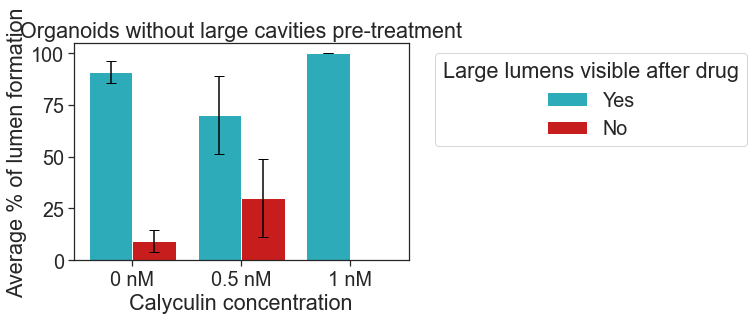

In [6]:
############################
#### Consider only organoids that did not form lumens before drug addition
############################



# Compute the sizes

## Population count, for each concentration, grouped by Batch_Well_ID, and depending on lumen formation

############## Function rework


# Load the masked df for organoids expected to form a lumen
df, mean_sewm_df_no_lumen_before = prepare_batch_weighted_df(excel_df.loc[(expected_lumen_mask) & (no_large_lumen_before_mask)], treatment_column_name='Drug concentration', batch_column_name='Batch_Well_ID', condition_column_name='Large lumens visible after drug addition (Yes/No/Uncertain)')


#####################################

## Indicate the "Large lumens visible" column
lumen_formed_column = "Large lumens visible after drug addition (Yes/No/Uncertain)"


## Re-sort the dataset to correctly add the error bars afterwards.
mean_sewm_df_no_lumen_before.sort_values(by=["Drug concentration", lumen_formed_column], ascending=[True,False], inplace=True)



##############################
#### Plotting section
##############################



with sns.axes_style("ticks"):
    g = sns.barplot(x="Drug concentration", y="Lumen formation weighted mean (%)", hue=lumen_formed_column,
                     palette=["tab:cyan", "xkcd:red"],
                   data=mean_sewm_df_no_lumen_before)

    for i, concentration in enumerate(mean_sewm_df_no_lumen_before["Drug concentration"].unique()):
        # Define subset of data
        print(f"Looking at {concentration}")
        subset = mean_sewm_df_no_lumen_before[mean_sewm_df_no_lumen_before["Drug concentration"] == concentration]
       # print(subset)    
        # Plot the custom error bars for each group
        #plt.errorbar(x=subset.index, y=subset["mean"], yerr=subset["std"], fmt="none", ecolor="black", capsize=5)
        plt.errorbar(x=np.array([i-0.2, i+0.2]), y=subset["Lumen formation weighted mean (%)"], yerr=subset["Standard error of the weighted mean (weighted std dev, %)"], fmt="none", ecolor="black", capsize=5)
        plt.ylabel("Average % of lumen formation")
        plt.xlabel("Calyculin concentration")
        plt.title("Organoids without large cavities pre-treatment")
        plt.legend(bbox_to_anchor=(1.05,1),loc="upper left",title="Large lumens visible after drug")
#        plt.legend(bbox_to_anchor=(1.05,1),loc="upper left",title="Large lumens visible after drug", fontsize=12)
        savefigure(graphs_folder, "forming_lumen_after_treatment_per_concentration_mean_sewm_no_lumen_before")


Didn't find the No condition for batch 220919_D6, at 0 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 220919_D2, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 221003_D2, at 0.5 nM. Adding the complement and setting the count to 0
Didn't find the No condition for batch 221003_D1, at 1 nM. Adding the complement and setting the count to 0
Looking at 0 nM


C:\Users\Samuel\anaconda3\lib\site-packages\numpy\core\_asarray.py:102: UserWarning: Warning: converting a masked element to nan.
  return array(a, dtype, copy=False, order=order)


Looking at 0.5 nM
Looking at 1 nM


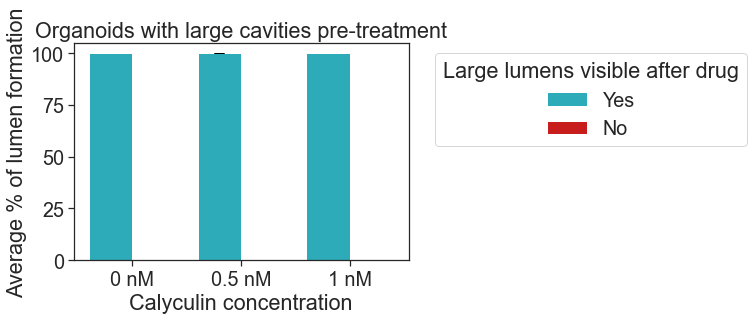

In [7]:
############################
#### Consider only organoids that DID form lumens before drug addition
############################



# Compute the sizes

## Population count, for each concentration, grouped by Batch_Well_ID, and depending on lumen formation

############## Function rework
large_lumen_before_mask = excel_df["Large lumens visible before drug addition"] == "Yes"

# Load the masked df for organoids expected to form a lumen
df, mean_sewm_df_with_lumen_before = prepare_batch_weighted_df(excel_df.loc[(expected_lumen_mask) & (large_lumen_before_mask)], treatment_column_name='Drug concentration', batch_column_name='Batch_Well_ID', condition_column_name='Large lumens visible after drug addition (Yes/No/Uncertain)')


#####################################

## Indicate the "Large lumens visible" column
lumen_formed_column = "Large lumens visible after drug addition (Yes/No/Uncertain)"


## Re-sort the dataset to correctly add the error bars afterwards.
mean_sewm_df_with_lumen_before.sort_values(by=["Drug concentration", lumen_formed_column], ascending=[True,False], inplace=True)



##############################
#### Plotting section
##############################



with sns.axes_style("ticks"):
    g = sns.barplot(x="Drug concentration", y="Lumen formation weighted mean (%)", hue=lumen_formed_column,
                     palette=["tab:cyan", "xkcd:red"],
                   data=mean_sewm_df_with_lumen_before)

    for i, concentration in enumerate(mean_sewm_df_with_lumen_before["Drug concentration"].unique()):
        # Define subset of data
        print(f"Looking at {concentration}")
        subset = mean_sewm_df_with_lumen_before[mean_sewm_df_with_lumen_before["Drug concentration"] == concentration]
       # print(subset)    
        # Plot the custom error bars for each group
        #plt.errorbar(x=subset.index, y=subset["mean"], yerr=subset["std"], fmt="none", ecolor="black", capsize=5)
        plt.errorbar(x=np.array([i-0.2, i+0.2]), y=subset["Lumen formation weighted mean (%)"], yerr=subset["Standard error of the weighted mean (weighted std dev, %)"], fmt="none", ecolor="black", capsize=5)
        plt.ylabel("Average % of lumen formation")
        plt.xlabel("Calyculin concentration")
        plt.title("Organoids with large cavities pre-treatment")
        plt.legend(bbox_to_anchor=(1.05,1),loc="upper left",title="Large lumens visible after drug")
#        plt.legend(bbox_to_anchor=(1.05,1),loc="upper left",title="Large lumens visible after drug", fontsize=12)
        savefigure(graphs_folder, "forming_lumen_after_treatment_per_concentration_mean_sewm_with_lumen_before")
